# DF-SA-MRFO-SAINT-DeepFM-GF — Pregnancy Outcome Prediction

## Install and import libraries

In [ ]:


import os, json, time, math, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)
import shap

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans",
                     "axes.titleweight": "bold", "axes.labelweight": "bold"})

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| PyTorch", torch.__version__, "| SHAP", shap.__version__)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), bbox_inches="tight")
    plt.show()

Device: cuda | PyTorch 2.11.0+cu130 | SHAP 0.54.1


## Experiment configuration

In [ ]:
TARGET = "Pregnancy_Outcome"

RUN_DFSAMRFO       = True
OPT_POP            = 10
OPT_ITERS          = 20        # iterations (T)
OPT_EPOCHS         = 50        # epochs per candidate
OPT_TRAIN_FRACTION = 1.0       # stratified fraction of the training subset
OPT_PATIENCE       = None         # early stopping

FINAL_EPOCHS       = 50
RES_ALPHA          = 0.10      # residual scaling coefficient
TAU                = 0.5       # decision threshold
EPS_CLIP           = 1e-7      # probability clipping

DEFAULT_HPARAMS = dict(lr=0.001, emb_dim=32, n_blocks=3, n_heads=4,
                      fm_hidden=128, dropout=0.20, batch_size=128, l2=1e-3)

# SHAP settings
SHAP_N_EXPLAIN    = 500        # test records
SHAP_N_BACKGROUND = 100        # background records

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "pregnancy_prediction_dataset.csv"

df = pd.read_csv(DATA_PATH) if DATA_PATH.lower().endswith(".csv") else pd.read_excel(DATA_PATH)
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)

id_like = [c for c in df.columns if c.lower() in ("id", "patient_id", "patientid", "record_id", "unnamed: 0")]
df = df.drop(columns=id_like)
print("Dropped identifier columns:", id_like)

# encode the target as 1 = Pregnant, 0 = Not Pregnant
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    t = df[TARGET].astype(str).str.strip().str.lower()
    df[TARGET] = t.map(lambda v: 0 if ("not" in v or v in ("0", "no", "negative")) else 1).astype(int)
CLASS_NAMES = ["Not Pregnant", "Pregnant"]
print(df[TARGET].value_counts().rename(index={0: "Not Pregnant (0)", 1: "Pregnant (1)"}))

Saving Pregnancy_Prediction_Dataset.csv to Pregnancy_Prediction_Dataset (1).csv
Shape: (50000, 41)
Dropped identifier columns: []
Pregnancy_Outcome
Pregnant (1)        34404
Not Pregnant (0)    15596
Name: count, dtype: int64


### Illustrative records

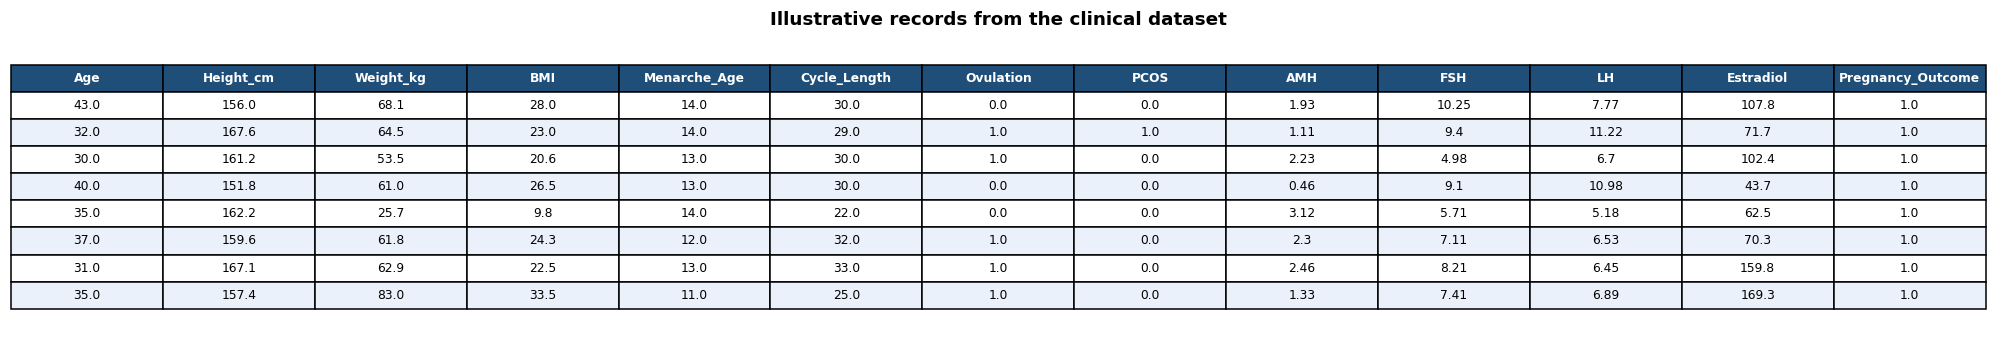

In [ ]:
display_cols = list(df.columns[:12]) + [TARGET] if TARGET not in df.columns[:12] else list(df.columns[:13])
sample = df[display_cols].head(8).round(2)
fig, ax = plt.subplots(figsize=(min(2 + 1.25 * len(display_cols), 22), 3.2))
ax.axis("off")
tbl = ax.table(cellText=sample.values, colLabels=sample.columns, loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8); tbl.scale(1, 1.4)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor("#1F4E79"); cell.set_text_props(color="white", weight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#EAF1FB")
plt.title("Illustrative records from the clinical dataset", pad=12)
save_fig("sample_records.png")

In [ ]:
pd.set_option("display.max_columns", None)
df.head()

,Age,Height_cm,Weight_kg,BMI,Menarche_Age,Cycle_Length,Ovulation,PCOS,AMH,FSH,LH,Estradiol,Progesterone,Prolactin,TSH,Testosterone,Insulin,Glucose,HbA1c,Vitamin_D,AFC,Ovarian_Volume,Endometrial_Thickness,Fibroids,Endometriosis,Ovarian_Cyst,Previous_Pregnancy,Miscarriage_History,Infertility_Years,Smoking,Alcohol,Exercise_Level,Stress_Level,Sleep_Hours,Diet_Quality,Systolic_BP,Diastolic_BP,Heart_Rate,Diabetes,Thyroid_Disorder,Pregnancy_Outcome
0,43,156.0,68.1,28.0,14,30,0,0,1.93,10.25,7.77,107.8,9.4,13.0,1.50,26.3,12.4,84.7,5.4,21.5,32,7.6,10.8,0,0,0,1,0,3.4,0,1,Moderate,High,6.7,Poor,108,89,66,0,0,1
1,32,167.6,64.5,23.0,14,29,1,1,1.11,9.40,11.22,71.7,15.7,20.6,2.79,52.5,17.3,91.5,5.9,34.9,14,11.0,9.8,0,0,1,0,0,0.3,0,0,High,High,7.8,Poor,113,59,93,0,0,1
2,30,161.2,53.5,20.6,13,30,1,0,2.23,4.98,6.70,102.4,6.6,17.2,0.20,54.3,14.3,119.8,4.9,25.6,17,8.5,10.2,0,0,0,0,0,1.1,0,0,Moderate,Moderate,5.2,Poor,120,83,63,0,0,1
3,40,151.8,61.0,26.5,13,30,0,0,0.46,9.10,10.98,43.7,10.6,19.3,2.09,41.5,10.7,96.2,5.0,29.0,12,7.6,7.7,0,0,0,1,0,0.5,0,0,Moderate,Low,8.6,Average,127,74,77,0,0,1
4,35,162.2,25.7,9.8,14,22,0,0,3.12,5.71,5.18,62.5,13.9,26.8,0.94,35.0,9.9,96.7,5.6,29.9,23,10.9,11.0,1,0,0,1,1,3.5,0,0,Low,Low,8.3,Average,103,82,73,0,0,1


In [ ]:
from IPython.display import display, HTML

preview = df.head(5).iloc[:, :10].copy()
preview["..."] = "..."
display(preview)
display(HTML(f"<p>{df.head(5).shape[0]} rows × {df.shape[1]} columns</p>"))

,Age,Height_cm,Weight_kg,BMI,Menarche_Age,Cycle_Length,Ovulation,PCOS,AMH,FSH,...
0,43,156.0,68.1,28.0,14,30,0,0,1.93,10.25,...
1,32,167.6,64.5,23.0,14,29,1,1,1.11,9.40,...
2,30,161.2,53.5,20.6,13,30,1,0,2.23,4.98,...
3,40,151.8,61.0,26.5,13,30,0,0,0.46,9.10,...
4,35,162.2,25.7,9.8,14,22,0,0,3.12,5.71,...


In [ ]:
df.head(5).iloc[:, -10:].style.hide(axis="index").format(
    lambda v: f"{v:g}" if isinstance(v, float) else v)

Exercise_Level,Stress_Level,Sleep_Hours,Diet_Quality,Systolic_BP,Diastolic_BP,Heart_Rate,Diabetes,Thyroid_Disorder,Pregnancy_Outcome
Moderate,High,6.7,Poor,108,89,66,0,0,1
High,High,7.8,Poor,113,59,93,0,0,1
Moderate,Moderate,5.2,Poor,120,83,63,0,0,1
Moderate,Low,8.6,Average,127,74,77,0,0,1
Low,Low,8.3,Average,103,82,73,0,0,1


## Exploratory data analysis

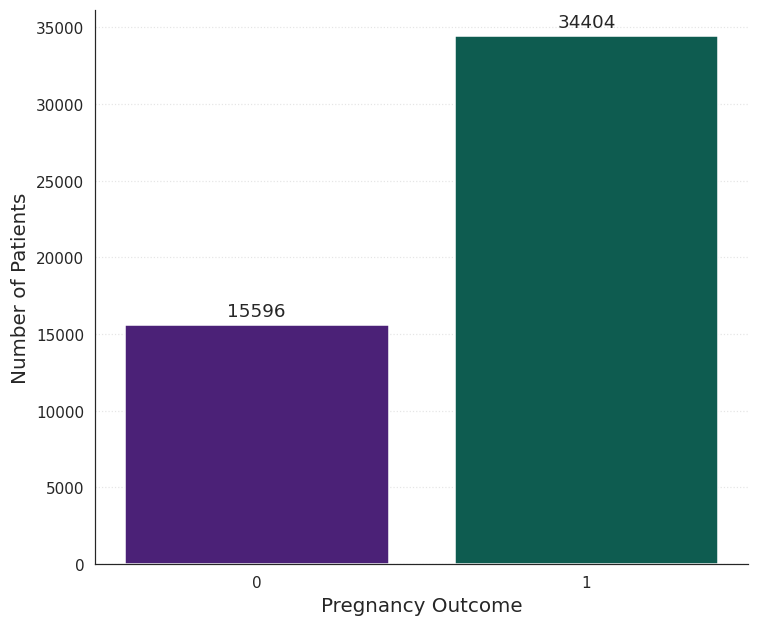

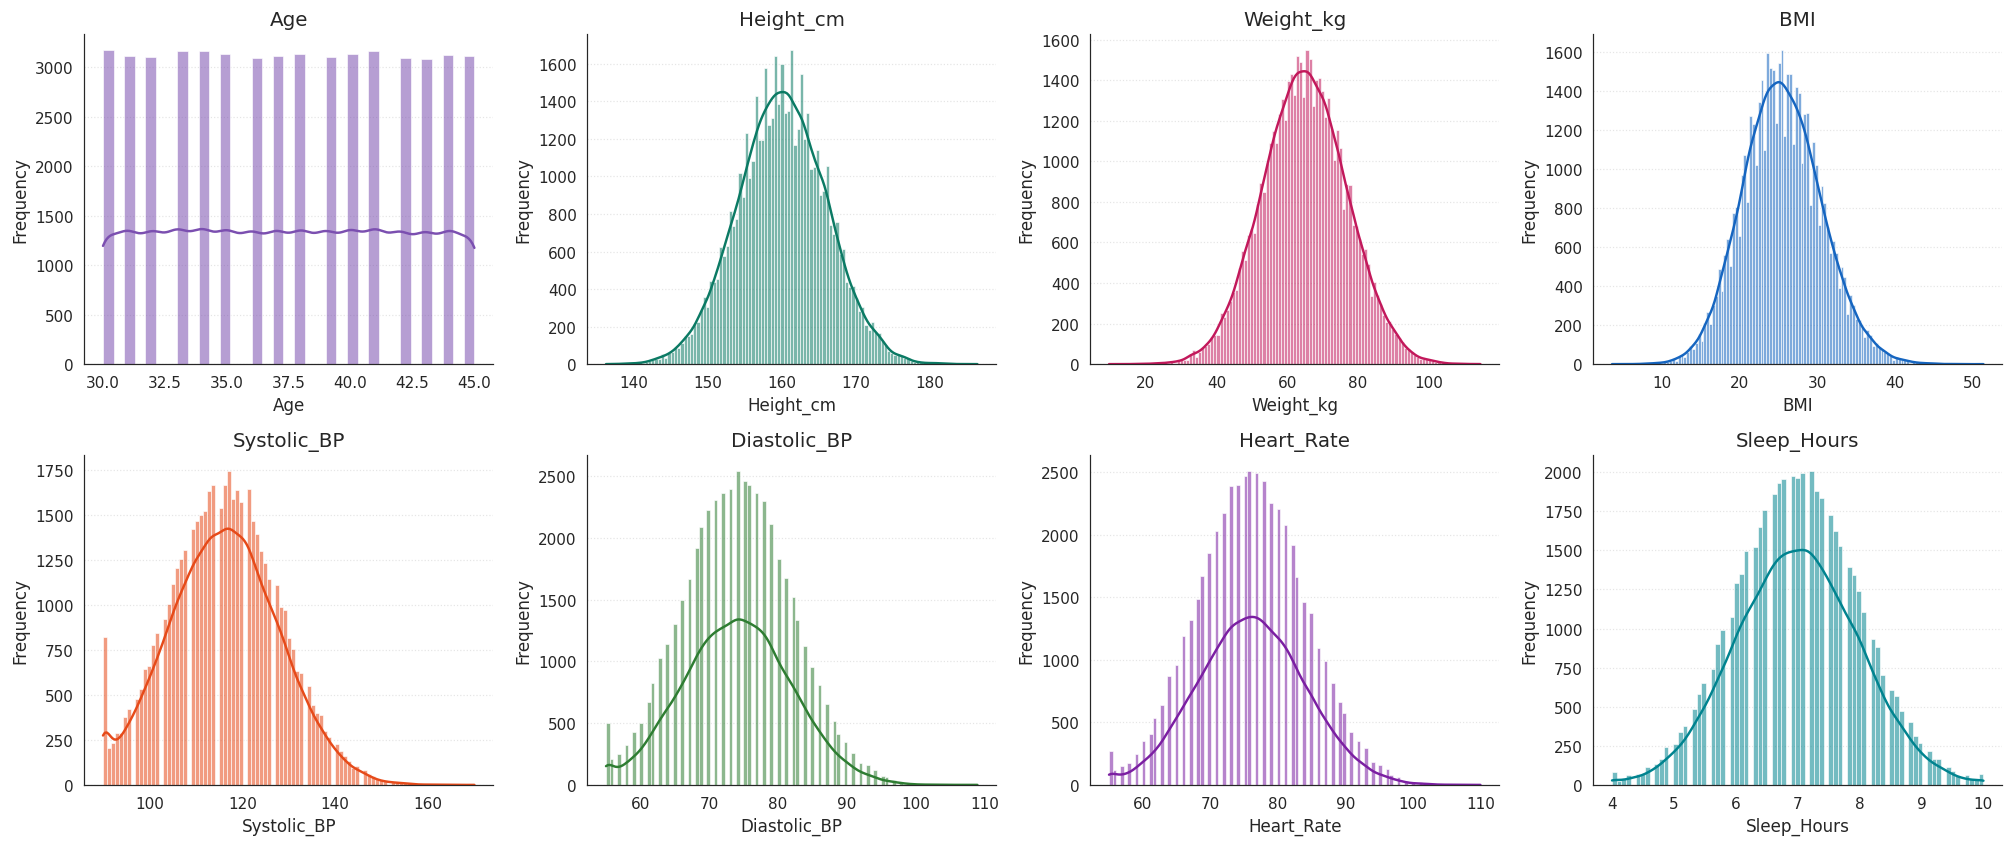

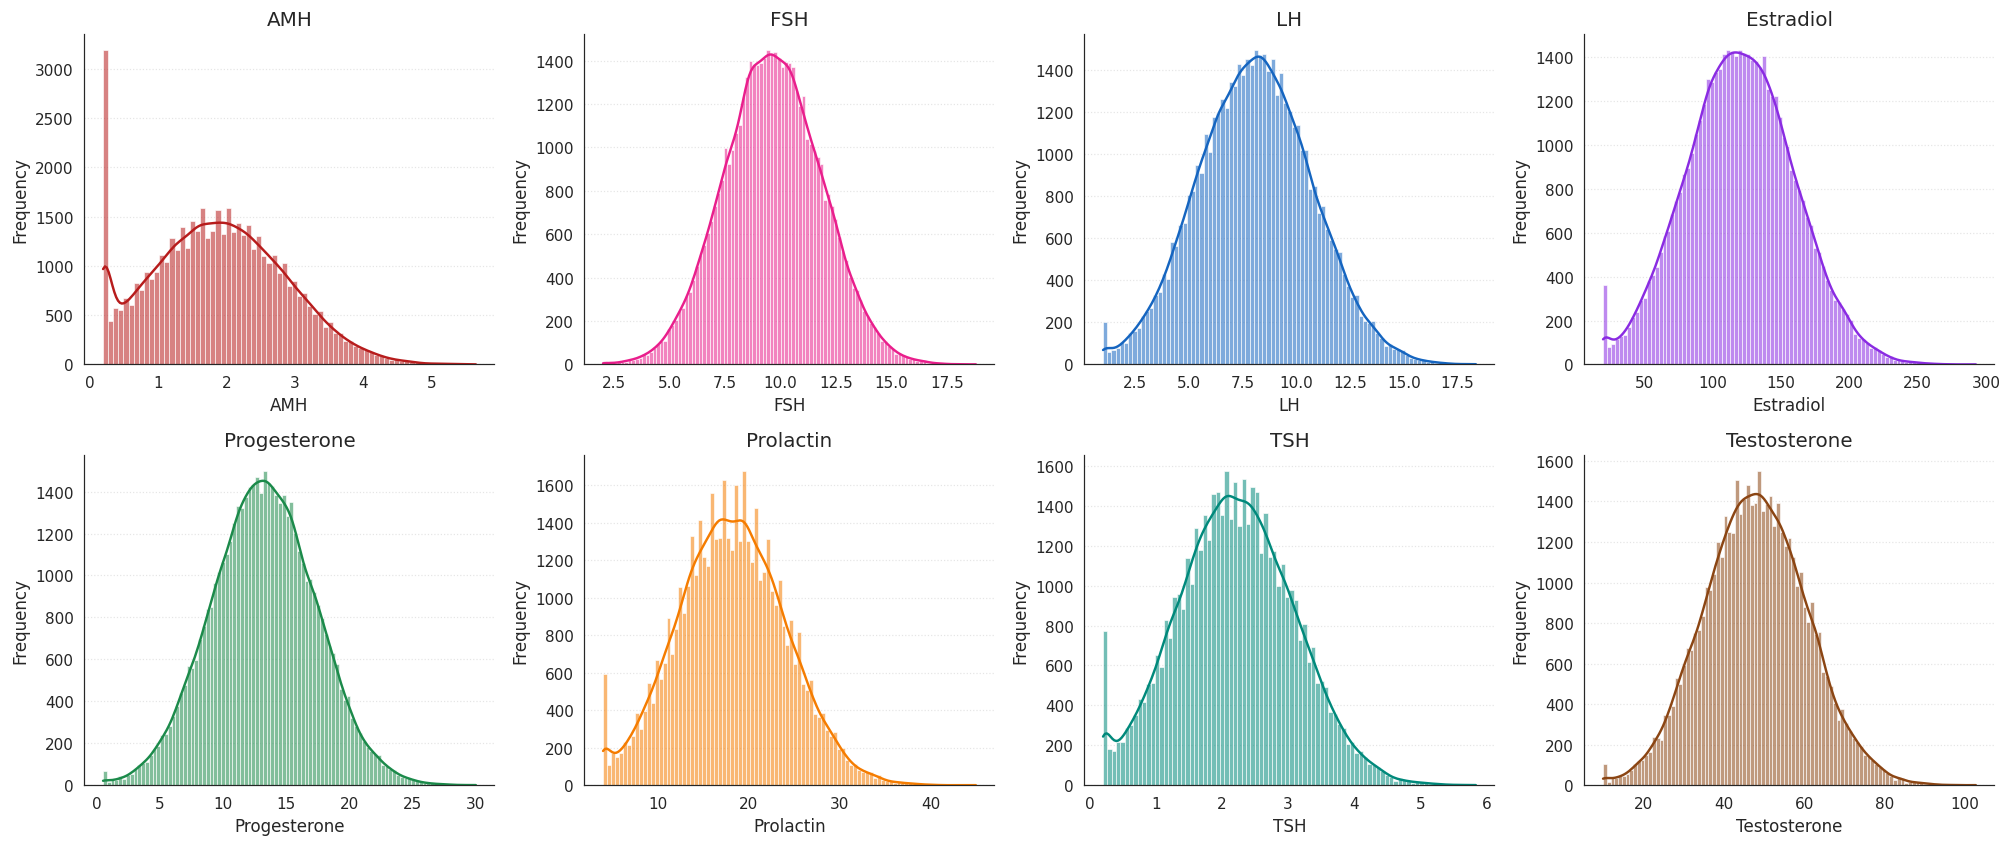

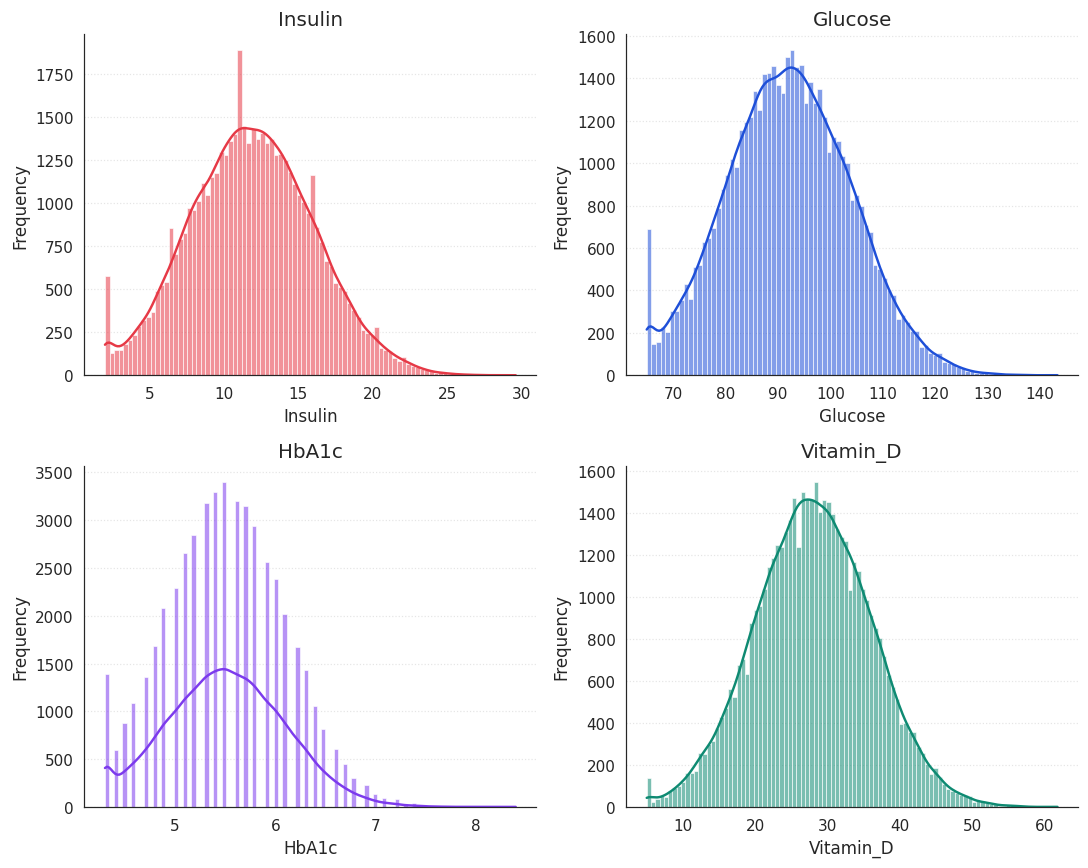

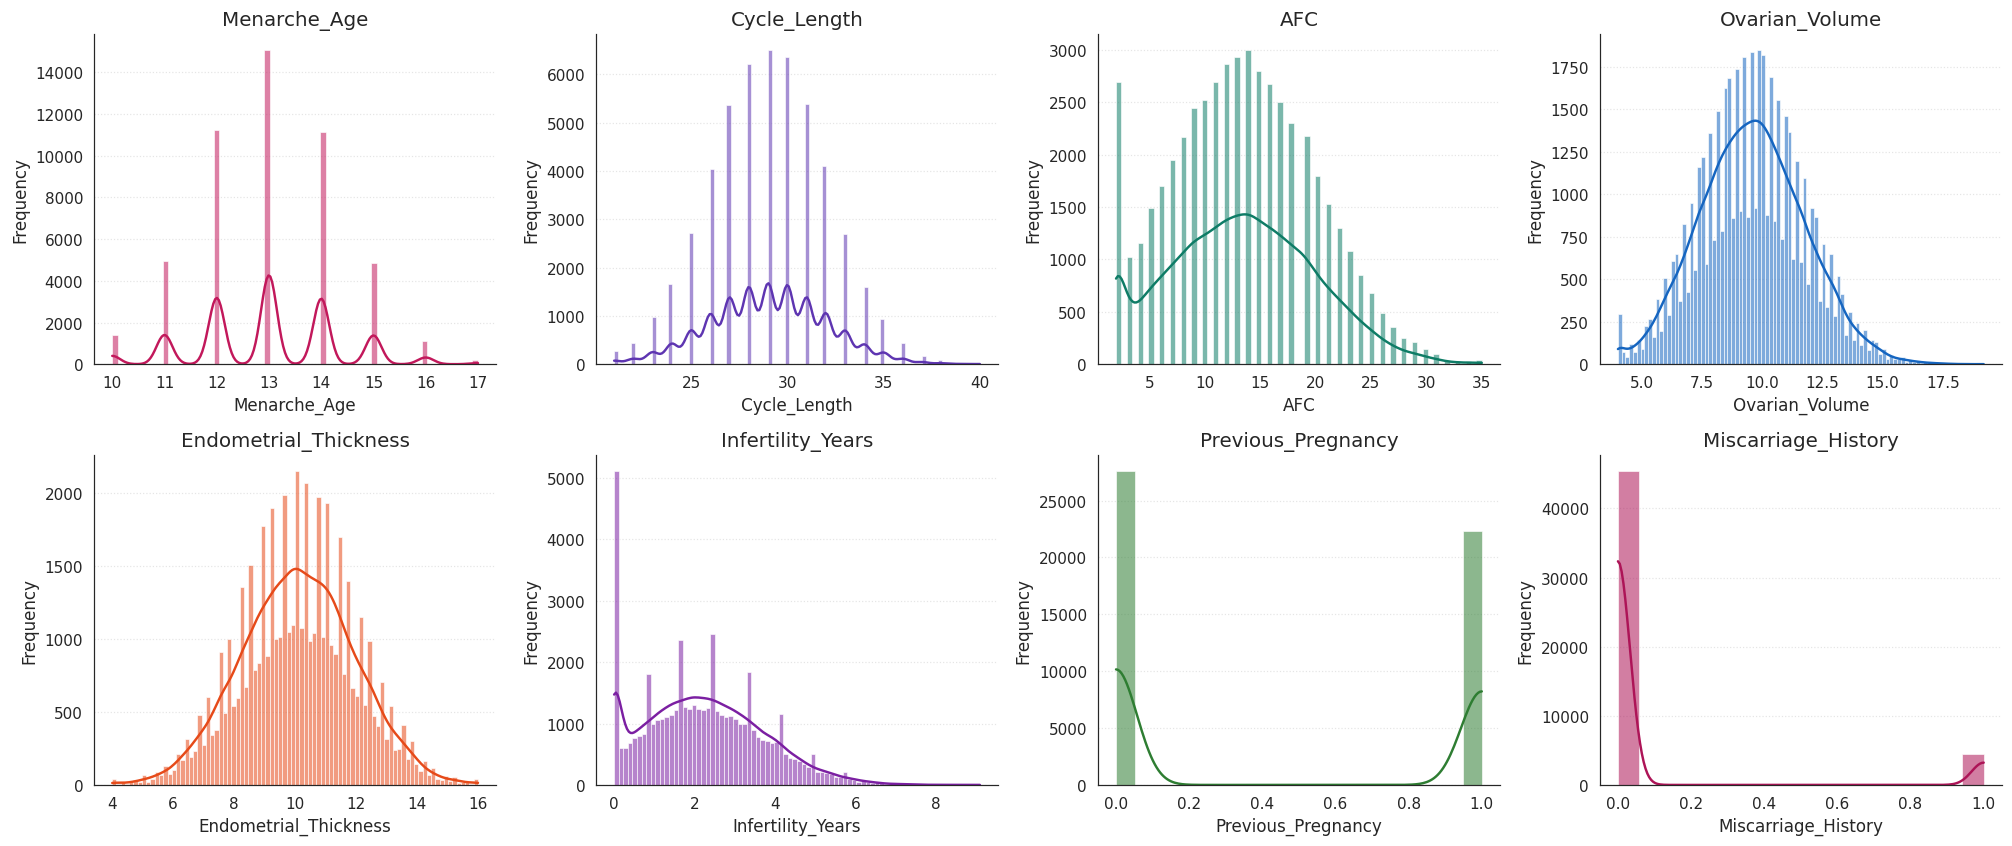

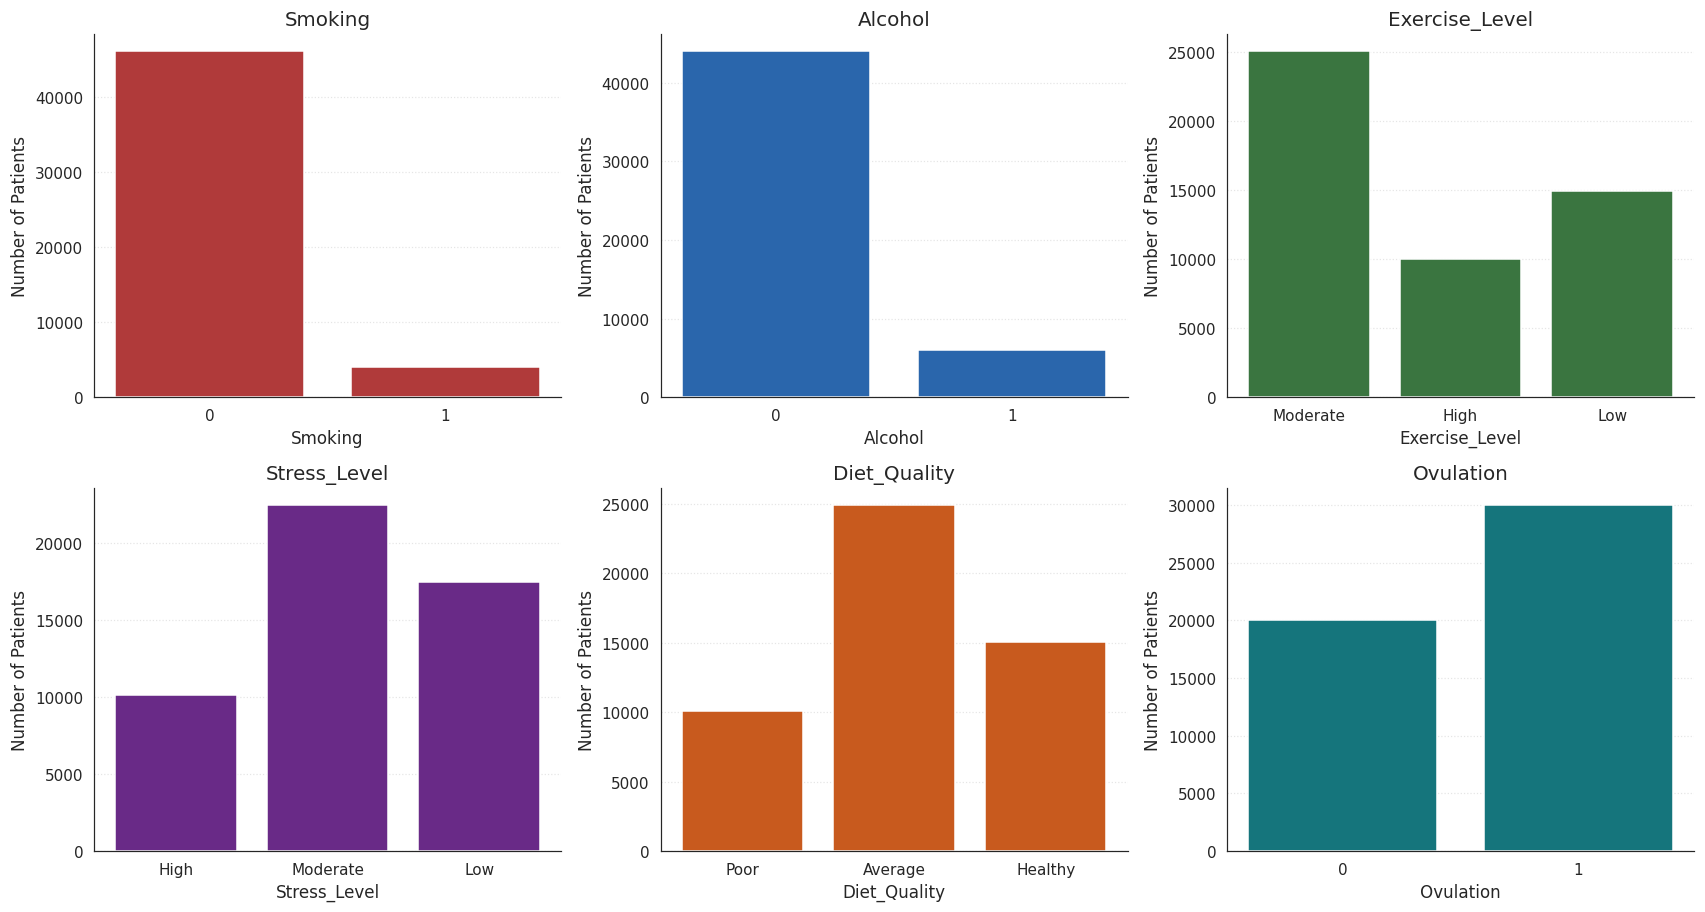

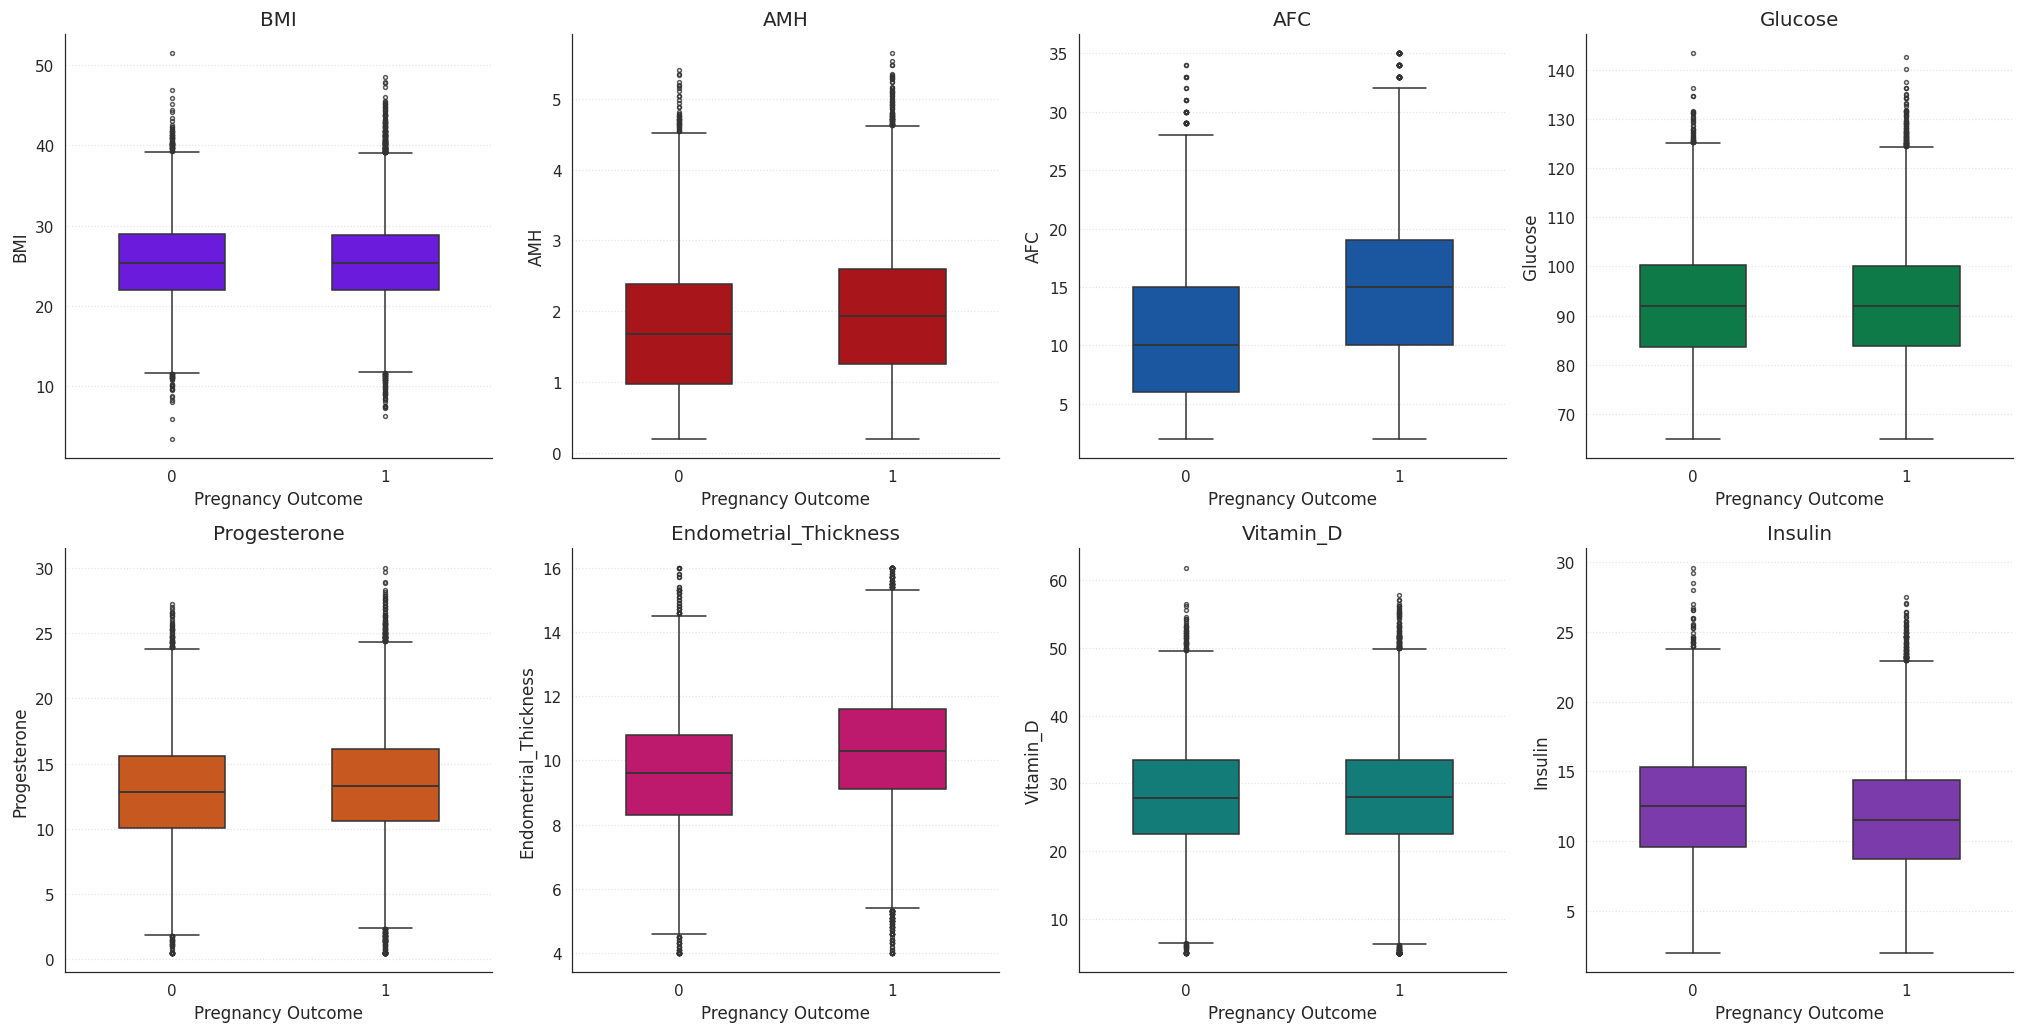

In [ ]:
def _norm(s): return "".join(ch for ch in s.lower() if ch.isalnum())
def find_cols(names):
    """Return the dataset columns that match the given clinical names """
    out, lookup = [], {_norm(c): c for c in df.columns}
    for n in names:
        key = _norm(n)
        hit = lookup.get(key) or next((c for k, c in lookup.items() if key in k), None)
        if hit and hit not in out and hit != TARGET:
            out.append(hit)
    return out

#  plot style
sns.set_style("white")
plt.rcParams.update({"axes.titleweight": "normal", "axes.labelweight": "normal",
                     "axes.titlesize": 13, "axes.labelsize": 11})

def style_ax(ax):
    sns.despine(ax=ax)
    ax.yaxis.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)
    ax.set_axisbelow(True)

COLORS = {
    # demographic / physiological / lifestyle
    "Age": "#7B4FB0", "Height_cm": "#0B7A64", "Weight_kg": "#C2185B", "BMI": "#1565C0",
    "Systolic_BP": "#E64A19", "Diastolic_BP": "#2E7D32", "Heart_Rate": "#7B1FA2", "Sleep_Hours": "#00838F",
    # hormonal
    "AMH": "#B71C1C", "FSH": "#E91E8C", "LH": "#1565C0", "Estradiol": "#8A2BE2",
    "Progesterone": "#1B8A4A", "Prolactin": "#F57C00", "TSH": "#00897B", "Testosterone": "#8B4513",
    # metabolic
    "Insulin": "#E63946", "Glucose": "#1E4FD8", "HbA1c": "#7C3AED", "Vitamin_D": "#0E8A72",
    # reproductive
    "Menarche_Age": "#C2185B", "Cycle_Length": "#5E35B1", "AFC": "#0E7C66", "Ovarian_Volume": "#1565C0",
    "Endometrial_Thickness": "#E64A19", "Infertility_Years": "#7B1FA2",
    "Previous_Pregnancy": "#2E7D32", "Miscarriage_History": "#AD1457",
}
CAT_COLORS = {"Smoking": "#B03A3A", "Alcohol": "#2A66AC", "Exercise_Level": "#3A7540",
              "Stress_Level": "#692A87", "Diet_Quality": "#C85A1E", "Ovulation": "#15757C"}
BOX_COLORS = {"BMI": "#6A1BDB", "AMH": "#A8151A", "AFC": "#1A57A0", "Glucose": "#0D7A47",
              "Progesterone": "#C7581F", "Endometrial_Thickness": "#BE1A6D", "Vitamin_D": "#137B78",
              "Insulin": "#7B3BAA"}
FALLBACK = sns.color_palette("tab10")

def color_for(col, table, i):
    for k, v in table.items():
        if _norm(k) == _norm(col):
            return v
    return FALLBACK[i % len(FALLBACK)]

def hist_grid(cols, fname, ncols=4, cell_w=4.6, cell_h=3.9):
    if not cols: return
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell_w * ncols, cell_h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for i, (ax, c) in enumerate(zip(axes, cols)):
        col = color_for(c, COLORS, i)
        sns.histplot(df[c].dropna(), kde=True, ax=ax, color=col, edgecolor="white", linewidth=0.4,
                     alpha=0.55, line_kws={"linewidth": 1.6})
        if ax.lines: ax.lines[-1].set_color(col)
        ax.set_title(c); ax.set_xlabel(c); ax.set_ylabel("Frequency")
        style_ax(ax)
    for ax in axes[len(cols):]: ax.axis("off")
    save_fig(fname)

# Class distribution
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 5.8))
bars = ax.bar([str(k) for k in counts.index], counts.values, color=["#4B2177", "#0E5C50"], width=0.8)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + counts.max() * 0.01, f"{v}", ha="center", va="bottom", fontsize=12)
ax.set_ylabel("Number of Patients", fontsize=13); ax.set_xlabel("Pregnancy Outcome", fontsize=13)
style_ax(ax)
save_fig("class_distribution.png")

# Numerical distributions by clinical group
hist_grid(find_cols(["Age", "Height_cm", "Weight_kg", "BMI", "Systolic_BP", "Diastolic_BP", "Heart_Rate", "Sleep_Hours"]),
          "demographic_physiological.png")
hist_grid(find_cols(["AMH", "FSH", "LH", "Estradiol", "Progesterone", "Prolactin", "TSH", "Testosterone"]),
          "hormonal.png")
hist_grid(find_cols(["Insulin", "Glucose", "HbA1c", "Vitamin_D"]),
          "metabolic.png", ncols=2, cell_w=5.0, cell_h=4.0)
hist_grid(find_cols(["Menarche_Age", "Cycle_Length", "AFC", "Ovarian_Volume", "Endometrial_Thickness",
                     "Infertility_Years", "Previous_Pregnancy", "Miscarriage_History"]),
          "reproductive.png")

# Lifestyle and reproductive status (categorical)
cat_eda = find_cols(["Smoking", "Alcohol", "Exercise_Level", "Stress_Level", "Diet_Quality", "Ovulation"])
if cat_eda:
    ncols = 3; nrows = math.ceil(len(cat_eda) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for i, (ax, c) in enumerate(zip(axes, cat_eda)):
        s = df[c].dropna()
        order = sorted(s.unique()) if pd.api.types.is_numeric_dtype(s) else list(pd.unique(s))
        vc = s.value_counts()
        ax.bar([str(o) for o in order], [vc[o] for o in order], color=color_for(c, CAT_COLORS, i), width=0.8)
        ax.set_title(c); ax.set_xlabel(c); ax.set_ylabel("Number of Patients")
        style_ax(ax)
    for ax in axes[len(cat_eda):]: ax.axis("off")
    save_fig("categorical.png")

# Boxplots by outcome class
box_cols = find_cols(["BMI", "AMH", "AFC", "Glucose", "Progesterone", "Endometrial_Thickness", "Vitamin_D", "Insulin"])
if box_cols:
    fig, axes = plt.subplots(2, 4, figsize=(18.5, 9.5))
    for i, (ax, c) in enumerate(zip(axes.ravel(), box_cols)):
        groups = [df.loc[df[TARGET] == k, c].dropna().values for k in (0, 1)]
        bp = ax.boxplot(groups, patch_artist=True, widths=0.5,
                        flierprops=dict(marker="o", markersize=2.5, markerfacecolor="none",
                                        markeredgecolor="#333333", alpha=0.8),
                        medianprops=dict(color="#333333", linewidth=1.2),
                        whiskerprops=dict(color="#333333"), capprops=dict(color="#333333"))
        for patch in bp["boxes"]:
            patch.set_facecolor(color_for(c, BOX_COLORS, i)); patch.set_edgecolor("#333333")
        ax.set_xticks([1, 2]); ax.set_xticklabels(["0", "1"])
        ax.set_title(c); ax.set_xlabel("Pregnancy Outcome"); ax.set_ylabel(c)
        style_ax(ax)
    for ax in axes.ravel()[len(box_cols):]: ax.axis("off")
    save_fig("boxplots.png")

## Stratified 70:15:15 partitioning

In [ ]:
X_all = df.drop(columns=[TARGET])
y_all = df[TARGET].values.astype(int)

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

split_tbl = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Records": [len(y_train), len(y_val), len(y_test)],
    "Not Pregnant (0)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Pregnant (1)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()]})

y_all = pd.concat([pd.Series(y_train), pd.Series(y_val), pd.Series(y_test)])

counts = y_all.value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)

summary = pd.DataFrame({
    "Class": ["Not Pregnant (0)", "Pregnant (1)"],
    "Records": counts.values,
    "Percentage": pct.values
})

print(split_tbl.to_string(index=False))
print(summary.to_string(index=False))

    Subset  Records  Not Pregnant (0)  Pregnant (1)
  Training    35000             10917         24083
Validation     7500              2339          5161
   Testing     7500              2340          5160
           Class  Records  Percentage
Not Pregnant (0)    15596        31.2
    Pregnant (1)    34404        68.8


## Leakage-free preprocessing


In [ ]:
print("Missing values in the complete dataset:", int(df.isna().sum().sum()))
print("Exact duplicate records:", int(df.duplicated().sum()))

MULTI_CAT_HINTS = ["exercise", "stress", "diet"]

num_cols, bin_cols, cat_cols = [], [], []
for c in X_train_raw.columns:
    s = X_train_raw[c]
    nun = s.dropna().nunique()
    if not pd.api.types.is_numeric_dtype(s):
        (bin_cols if nun <= 2 else cat_cols).append(c)
    elif any(h in c.lower() for h in MULTI_CAT_HINTS) and nun <= 10:
        cat_cols.append(c)
    elif nun <= 2:
        bin_cols.append(c)
    else:
        num_cols.append(c)
print(f"Continuous: {len(num_cols)} | Binary: {len(bin_cols)} | Multi-category: {len(cat_cols)}")
print("Multi-category columns:", cat_cols)

class TabularPreprocessor:
    def fit(self, X):
        self.medians = X[num_cols].median()
        self.bin_maps, self.bin_modes = {}, {}
        for c in bin_cols:
            vals = sorted(X[c].dropna().unique(), key=lambda v: str(v))
            pos = [v for v in vals if str(v).strip().lower() in ("1", "1.0", "yes", "true", "y", "present", "positive")]
            if pos:
                self.bin_maps[c] = {v: (1 if v in pos else 0) for v in vals}
            else:
                self.bin_maps[c] = {v: i for i, v in enumerate(vals)}
            self.bin_modes[c] = X[c].mode().iloc[0]
        self.cat_modes = {c: X[c].mode().iloc[0] for c in cat_cols}
        self.cat_vocab = {c: {v: i for i, v in enumerate(sorted(X[c].dropna().unique(), key=lambda v: str(v)))}
                          for c in cat_cols}
        Xn = X[num_cols].fillna(self.medians).astype(float)
        self.mu, self.sigma = Xn.mean(), Xn.std(ddof=0)
        return self

    def raw_imputed(self, X):
        """Imputed but unscaled values (used for SHAP display)."""
        out = pd.DataFrame(index=X.index)
        for c in num_cols: out[c] = X[c].fillna(self.medians[c]).astype(float)
        for c in bin_cols: out[c] = X[c].fillna(self.bin_modes[c]).map(self.bin_maps[c]).fillna(0).astype(float)
        for c in cat_cols:
            out[c] = X[c].fillna(self.cat_modes[c]).map(self.cat_vocab[c]).fillna(len(self.cat_vocab[c])).astype(float)
        return out

    def transform(self, X):
        R = self.raw_imputed(X)
        x_num = ((R[num_cols] - self.mu) / (self.sigma + 1e-8)).values if num_cols else np.zeros((len(X), 0))
        x_bin = R[bin_cols].values if bin_cols else np.zeros((len(X), 0))
        x_cont = np.hstack([x_num, x_bin]).astype(np.float32)
        x_cat = R[cat_cols].values.astype(np.int64) if cat_cols else np.zeros((len(X), 0), np.int64)
        return x_cont, x_cat

prep = TabularPreprocessor().fit(X_train_raw)
Xc_tr, Xk_tr = prep.transform(X_train_raw)
Xc_va, Xk_va = prep.transform(X_val_raw)
Xc_te, Xk_te = prep.transform(X_test_raw)

CONT_FEATURES = num_cols + bin_cols
CAT_FEATURES = cat_cols
FEATURE_NAMES = CONT_FEATURES + CAT_FEATURES
CAT_CARDINALITIES = [len(prep.cat_vocab[c]) + 1 for c in cat_cols]
print("Continuous tensor:", Xc_tr.shape, "| Categorical tensor:", Xk_tr.shape)

# class weights: w_c = N / (K * N_c)
N_tr, K = len(y_train), 2
CLASS_W = torch.tensor([N_tr / (K * (y_train == c).sum()) for c in (0, 1)], dtype=torch.float32)
print("Class weights  w0 = %.4f, w1 = %.4f" % tuple(CLASS_W.tolist()))

Missing values in the complete dataset: 0
Exact duplicate records: 0
Continuous: 26 | Binary: 11 | Multi-category: 3
Multi-category columns: ['Exercise_Level', 'Stress_Level', 'Diet_Quality']
Continuous tensor: (35000, 37) | Categorical tensor: (35000, 3)
Class weights  w0 = 1.6030, w1 = 0.7267


## Model — SAINT branch, DeepFM branch, Adaptive Gated Feature Fusion, classification head

In [ ]:
class FeatureTokenizer(nn.Module):
    """Numeric projection e = x·w_j + b_j and categorical embedding lookup e = E_j[x]."""
    def __init__(self, n_cont, cat_cards, d):
        super().__init__()
        self.n_cont = n_cont
        self.w = nn.Parameter(torch.randn(n_cont, d) * 0.02)
        self.b = nn.Parameter(torch.zeros(n_cont, d))
        self.cat_emb = nn.ModuleList([nn.Embedding(k, d) for k in cat_cards])
    def forward(self, x_cont, x_cat):
        tok = [x_cont.unsqueeze(-1) * self.w + self.b] if self.n_cont else []
        if len(self.cat_emb):
            tok.append(torch.stack([emb(x_cat[:, j]) for j, emb in enumerate(self.cat_emb)], dim=1))
        return torch.cat(tok, dim=1)

class SAINTBlock(nn.Module):
    """Feature-wise MHA → inter-sample MHA → residual + LN → FFN + LN."""
    def __init__(self, p, d, heads, dropout):
        super().__init__()
        self.feat_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_in = nn.Linear(p * d, d)
        self.row_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_out = nn.Linear(d, p * d)
        self.ln1 = nn.LayerNorm(d); self.ln2 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, H):
        B, p, d = H.shape
        Hf, _ = self.feat_attn(H, H, H)
        r = self.row_proj_in(Hf.reshape(B, p * d)).unsqueeze(0)
        Zr, _ = self.row_attn(r, r, r)
        Hr = Hf + self.row_proj_out(Zr.squeeze(0)).reshape(B, p, d)
        U = self.ln1(H + self.drop(Hr))
        return self.ln2(U + self.drop(self.ffn(U)))

class SAINTBranch(nn.Module):
    def __init__(self, n_cont, cat_cards, d, n_blocks, heads, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.col_emb = nn.Parameter(torch.randn(1, p, d) * 0.02)
        self.blocks = nn.ModuleList([SAINTBlock(p, d, heads, dropout) for _ in range(n_blocks)])
        self.out_dim = d
    def forward(self, x_cont, x_cat):
        H = self.tok(x_cont, x_cat) + self.col_emb
        for blk in self.blocks: H = blk(H)
        return H.mean(dim=1)

class DeepFMBranch(nn.Module):
    """First-order + FM second-order + deep MLP; h_D = Concat(y1, y2, h_deep)."""
    def __init__(self, n_cont, cat_cards, d, hidden, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.lin_cont = nn.Linear(n_cont, 1) if n_cont else None
        self.lin_cat = nn.ModuleList([nn.Embedding(k, 1) for k in cat_cards])
        self.mlp = nn.Sequential(nn.Linear(p * d, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.BatchNorm1d(hidden // 2), nn.ReLU(), nn.Dropout(dropout))
        self.out_dim = 2 + hidden // 2
    def forward(self, x_cont, x_cat):
        B = x_cont.shape[0]
        y1 = self.lin_cont(x_cont) if self.lin_cont is not None else torch.zeros(B, 1, device=x_cont.device)
        for j, emb in enumerate(self.lin_cat): y1 = y1 + emb(x_cat[:, j])
        V = self.tok(x_cont, x_cat)
        y2 = 0.5 * (V.sum(1).pow(2) - V.pow(2).sum(1)).sum(1, keepdim=True)
        h_deep = self.mlp(V.reshape(B, -1))
        return torch.cat([y1, y2, h_deep], dim=1)

class AdaptiveGatedFusion(nn.Module):
    """z_s, z_d projections, sigmoid gate, gated sum and residual pathway."""
    def __init__(self, d_s, d_d, d_f, alpha=RES_ALPHA):
        super().__init__()
        self.Ws, self.Wd = nn.Linear(d_s, d_f), nn.Linear(d_d, d_f)
        self.Wg, self.Wr = nn.Linear(2 * d_f, d_f), nn.Linear(2 * d_f, d_f)
        self.alpha = alpha
    def forward(self, r_saint, r_deepfm, return_gate=False):
        zs, zd = self.Ws(r_saint), self.Wd(r_deepfm)
        z = torch.cat([zs, zd], dim=1)
        g = torch.sigmoid(self.Wg(z))
        r = g * zs + (1 - g) * zd + self.alpha * self.Wr(z)
        return (r, g) if return_gate else r

class SAINTDeepFMGF(nn.Module):
    def __init__(self, n_cont, cat_cards, hp):
        super().__init__()
        d = hp["emb_dim"]
        self.saint = SAINTBranch(n_cont, cat_cards, d, hp["n_blocks"], hp["n_heads"], hp["dropout"])
        self.deepfm = DeepFMBranch(n_cont, cat_cards, d, hp["fm_hidden"], hp["dropout"])
        self.fusion = AdaptiveGatedFusion(self.saint.out_dim, self.deepfm.out_dim, d)
        self.head = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Dropout(hp["dropout"]), nn.Linear(d, 1))
    def forward(self, x_cont, x_cat):
        return self.head(self.fusion(self.saint(x_cont, x_cat), self.deepfm(x_cont, x_cat))).squeeze(1)

## Training utilities — class-weighted BCE + L2, fixed deterministic evaluation batches

In [ ]:
def make_loader(xc, xk, y, batch_size, shuffle):
    ds = TensorDataset(torch.from_numpy(xc), torch.from_numpy(xk), torch.from_numpy(y.astype(np.float32)))
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g, drop_last=False)

def weighted_bce(logits, y):
    p = torch.sigmoid(logits.float()).clamp(EPS_CLIP, 1 - EPS_CLIP)
    w = torch.where(y > 0.5, CLASS_W[1], CLASS_W[0]).to(logits.device)
    return -(w * (y * torch.log(p) + (1 - y) * torch.log(1 - p))).mean()

def l2_penalty(model, lam):
    return lam * sum((W ** 2).sum() for n, W in model.named_parameters() if W.dim() > 1 and "emb" not in n)

@torch.no_grad()
def predict_proba(model, xc, xk, batch_size):
    model.eval(); out = []
    for i in range(0, len(xc), batch_size):
        c = torch.from_numpy(xc[i:i + batch_size]).to(DEVICE)
        k = torch.from_numpy(xk[i:i + batch_size]).to(DEVICE)
        out.append(torch.sigmoid(model(c, k)).float().cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot_loss, n, correct = 0.0, 0, 0
    for c, k, y in loader:
        c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
        logits = model(c, k)
        tot_loss += weighted_bce(logits, y).item() * len(y); n += len(y)
        correct += ((torch.sigmoid(logits) >= TAU).float() == y).sum().item()
    return tot_loss / n, correct / n

def train_model(hp, data, epochs, patience=None, verbose=False, seed=SEED):
    set_seed(seed)
    (xc_tr, xk_tr, ytr), (xc_va, xk_va, yva) = data
    tr_loader = make_loader(xc_tr, xk_tr, ytr, hp["batch_size"], shuffle=True)
    va_loader = make_loader(xc_va, xk_va, yva, hp["batch_size"], shuffle=False)
    model = SAINTDeepFMGF(xc_tr.shape[1], CAT_CARDINALITIES, hp).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, wait = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        model.train(); tl, tc, tn = 0.0, 0, 0
        for c, k, y in tr_loader:
            c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(c, k)
            loss = weighted_bce(logits, y) + l2_penalty(model, hp["l2"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += weighted_bce(logits.detach(), y).item() * len(y); tn += len(y)
            tc += ((torch.sigmoid(logits.detach()) >= TAU).float() == y).sum().item()
        vl, va = evaluate(model, va_loader)
        hist["train_loss"].append(tl / tn); hist["train_acc"].append(tc / tn)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if verbose:
            print(f"Epoch {ep:02d}/{epochs} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if vl < best_loss - 1e-6:
            best_loss, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if patience and wait >= patience: break
    model.load_state_dict(best_state)
    return model, hist, best_loss

## Bio-inspired DF-SA-MRFO hyperparameter optimization


In [ ]:
SEARCH_SPACE = [  # name, low, high, type
    ("lr",         1e-4, 2e-3, "log"),
    ("emb_dim",    16,   128,  "int"),
    ("n_blocks",   2,    6,    "int"),
    ("n_heads",    2,    8,    "int"),
    ("fm_hidden",  64,   512,  "int"),
    ("dropout",    0.10, 0.50, "float"),
    ("batch_size", 64,   256,  "int"),
    ("l2",         1e-6, 1e-2, "log"),
]
DIM = len(SEARCH_SPACE)

def snap(v, choices):
    return min(choices, key=lambda c: abs(c - v))

def decode(pos):
    hp = {}
    for v, (name, lo, hi, kind) in zip(np.clip(pos, 0, 1), SEARCH_SPACE):
        if kind == "log":   hp[name] = float(10 ** (np.log10(lo) + v * (np.log10(hi) - np.log10(lo))))
        elif kind == "int": hp[name] = int(round(lo + v * (hi - lo)))
        else:               hp[name] = float(lo + v * (hi - lo))

    hp["emb_dim"]    = snap(hp["emb_dim"], [16, 32, 64, 128])
    hp["n_heads"]    = snap(hp["n_heads"], [h for h in (2, 4, 8) if hp["emb_dim"] % h == 0])
    hp["fm_hidden"]  = max(64, int(64 * round(hp["fm_hidden"] / 64)))
    hp["batch_size"] = int(32 * round(hp["batch_size"] / 32))
    hp["lr"]         = round(hp["lr"], 4)
    hp["dropout"]    = round(round(hp["dropout"] / 0.05) * 0.05, 2)
    hp["l2"]         = float(f"{hp['l2']:.0e}")
    return hp

def encode(hp):
    pos = []
    for name, lo, hi, kind in SEARCH_SPACE:
        v = hp[name]
        pos.append((np.log10(v) - np.log10(lo)) / (np.log10(hi) - np.log10(lo)) if kind == "log" else (v - lo) / (hi - lo))
    return np.clip(np.array(pos), 0, 1)

if OPT_TRAIN_FRACTION < 1.0:
    idx_sub, _ = train_test_split(np.arange(len(y_train)), train_size=OPT_TRAIN_FRACTION,
                                  stratify=y_train, random_state=SEED)
else:
    idx_sub = np.arange(len(y_train))
OPT_DATA = ((Xc_tr[idx_sub], Xk_tr[idx_sub], y_train[idx_sub]), (Xc_va, Xk_va, y_val))

_fitness_cache, OPT_LOG = {}, []
def fitness(pos):
    """F(θ) = validation loss of the configuration; identical decoded configurations are cached."""
    hp = decode(pos); key = json.dumps(hp, sort_keys=True)
    if key not in _fitness_cache:
        t0 = time.time()
        _, _, vloss = train_model(hp, OPT_DATA, OPT_EPOCHS, patience=OPT_PATIENCE)
        _fitness_cache[key] = vloss
        OPT_LOG.append({**hp, "val_loss": vloss, "seconds": round(time.time() - t0, 1)})
        pd.DataFrame(OPT_LOG).to_csv(os.path.join(OUT_DIR, "dfsamrfo_evaluations.csv"), index=False)
    return _fitness_cache[key]

def df_sa_mrfo(Q=OPT_POP, T=OPT_ITERS, omega_min=0.5, omega_max=2.0, rho=0.20, alpha0=1.0, beta0=0.50,
               xi0=0.10, tau_s=1e-4, stall_iters=5, disp_scale=0.05, eps=1e-12, seed=SEED):
    rng = np.random.default_rng(seed)
    theta = rng.random((Q, DIM))
    fit = np.array([fitness(th) for th in theta])
    b = int(np.argmin(fit)); best_pos, best_fit = theta[b].copy(), fit[b]
    D0 = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1))
    beta, stall = beta0, 0
    history = [{"iter": 0, "best_val_loss": float(best_fit), "diversity": 1.0, "success_rate": None}]
    for t in range(1, T + 1):
        prev_best = best_fit
        Dt = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1))
        delta = Dt / (D0 + eps)
        omega = float(np.clip(1 - delta, omega_min, omega_max))
        alpha = alpha0 * (1 - t / T) + omega * t / T
        p_explore = alpha / (alpha + beta)
        s = np.zeros(Q); disp = np.zeros_like(theta)
        for q in range(Q):
            if rng.random() < p_explore:
                r = rng.choice([i for i in range(Q) if i != q])
                trial = theta[q] + alpha * rng.random(DIM) * (theta[r] - theta[q])
            else:
                trial = theta[q] + beta * rng.random(DIM) * (best_pos - theta[q])
            trial = np.clip(trial, 0, 1)
            f_trial = fitness(trial)
            if f_trial < fit[q]:
                s[q] = 1; disp[q] = trial - theta[q]; theta[q], fit[q] = trial, f_trial
        SR = s.mean()
        gamma = beta * SR
        beta = (1 - rho) * beta + rho * SR
        mean_dir = disp.sum(0) / (s.sum() + eps) if s.sum() > 0 else np.zeros(DIM)
        for q in range(Q):
            new = theta[q] + gamma * mean_dir
            new = new + omega * rng.normal(0, disp_scale, DIM)
            new = np.clip(new, 0, 1)
            f_new = fitness(new)
            if f_new < fit[q]:
                theta[q], fit[q] = new, f_new
            if f_new < best_fit: best_pos, best_fit = new.copy(), f_new
        b = int(np.argmin(fit))
        if fit[b] < best_fit: best_pos, best_fit = theta[b].copy(), fit[b]
        stall = stall + 1 if abs(prev_best - best_fit) < tau_s else 0
        if stall >= stall_iters:
            xi = xi0 * (1 - t / T)
            worst = np.argsort(fit)[-(Q // 2):]
            for q in worst:
                theta[q] = np.clip(best_pos + xi * rng.uniform(-1, 1, DIM), 0, 1)
                fit[q] = fitness(theta[q])
                if fit[q] < best_fit: best_pos, best_fit = theta[q].copy(), fit[q]
            stall = 0
        history.append({"iter": t, "best_val_loss": float(best_fit), "diversity": float(delta), "success_rate": float(SR)})
    return decode(best_pos), best_fit, history

if RUN_DFSAMRFO:
    t0 = time.time()
    BEST_HP, BEST_FIT, CONV_HISTORY = df_sa_mrfo()
    print(f"DF-SA-MRFO finished in {(time.time() - t0) / 60:.1f} min — {len(_fitness_cache)} unique configurations trained")
else:
    BEST_HP, BEST_FIT, CONV_HISTORY = dict(DEFAULT_HPARAMS), None, []
pd.DataFrame(CONV_HISTORY).to_csv(os.path.join(OUT_DIR, "dfsamrfo_convergence.csv"), index=False)

hp_tbl = pd.DataFrame({"Hyperparameter": ["Learning Rate", "Embedding Dimension", "Number of SAINT Blocks",
                                          "Number of Attention Heads", "DeepFM Hidden Units", "Dropout Rate",
                                          "Batch Size", "L2 Regularization Coefficient"],
                       "Optimized Value": [BEST_HP[k] for k in ["lr", "emb_dim", "n_blocks", "n_heads",
                                                                "fm_hidden", "dropout", "batch_size", "l2"]]})
print(hp_tbl.to_string(index=False))

DF-SA-MRFO finished in 302.8 min — 419 unique configurations trained
               Hyperparameter  Optimized Value
                Learning Rate           0.0008
          Embedding Dimension          64.0000
       Number of SAINT Blocks           4.0000
    Number of Attention Heads           4.0000
          DeepFM Hidden Units         256.0000
                 Dropout Rate           0.3000
                   Batch Size         128.0000
L2 Regularization Coefficient           0.0001


## Standard MRFO comparator

In [ ]:
from IPython.display import display
import numpy as np
import pandas as pd
import os
import json
import time
RUN_MRFO = True
MRFO_HPARAMS = dict(DEFAULT_HPARAMS)

# ---- MRFO implementation ----
def mrfo(Q=OPT_POP, T=OPT_ITERS, S=2.0, seed=SEED, eps=1e-12):
    global N_EVALS; N_EVALS = 0
    rng = np.random.default_rng(seed)
    X = rng.random((Q, DIM))
    fit = np.array([fitness(x) for x in X])
    b = int(np.argmin(fit)); best_pos, best_fit = X[b].copy(), fit[b]
    history = [{"iter": 0, "best_val_loss": float(best_fit)}]
    for t in range(1, T + 1):
        for i in range(Q):
            ahead = best_pos if i == 0 else X[i - 1]
            if rng.random() < 0.5:
                r1 = rng.random()
                beta = 2 * np.exp(r1 * (T - t + 1) / T) * np.sin(2 * np.pi * r1)
                ref = rng.random(DIM) if t / T < rng.random() else best_pos
                trial = ref + rng.random(DIM) * (ahead - X[i]) + beta * (ref - X[i])
            else:
                alpha = 2 * rng.random(DIM) * np.sqrt(np.abs(np.log(rng.random(DIM) + eps)))
                trial = X[i] + rng.random(DIM) * (ahead - X[i]) + alpha * (best_pos - X[i])
            trial = np.clip(trial, 0, 1); f_trial = fitness(trial)
            if f_trial < fit[i]: X[i], fit[i] = trial, f_trial
            if f_trial < best_fit: best_pos, best_fit = trial.copy(), f_trial
        for i in range(Q):
            trial = np.clip(X[i] + S * (rng.random() * best_pos - rng.random() * X[i]), 0, 1)
            f_trial = fitness(trial)
            if f_trial < fit[i]: X[i], fit[i] = trial, f_trial
            if f_trial < best_fit: best_pos, best_fit = trial.copy(), f_trial
        history.append({"iter": t, "best_val_loss": float(best_fit)})
    return decode(best_pos), best_fit, history
_fitness_cache.clear(); OPT_LOG.clear()
EVAL_CSV = "mrfo_evaluations.csv"
# run MRFO
if RUN_MRFO:
    MRFO_BEST, MRFO_FIT, MRFO_HISTORY = mrfo()
    pd.DataFrame(OPT_LOG).to_csv(os.path.join(OUT_DIR, EVAL_CSV), index=False)
else:
    MRFO_BEST = dict(MRFO_HPARAMS)
 # MRFO hyperparameter configuration
def _fmt(k, v):
    return f"{v:.4f}" if k in ("lr", "l2") else f"{v:.2f}" if k == "dropout" else int(v)

KEYS  = ["lr", "emb_dim", "n_blocks", "n_heads", "fm_hidden", "dropout", "batch_size", "l2"]
NAMES = ["Learning Rate", "Embedding Dimension", "Number of SAINT Blocks", "Number of Attention Heads",
         "DeepFM Hidden Units", "Dropout Rate", "Batch Size", "L2 Regularization Coefficient"]
mrfo_tbl = pd.DataFrame({
    "Hyperparameter": NAMES,
    "MRFO": [_fmt(k, MRFO_BEST[k]) for k in KEYS]})

mrfo_tbl.to_csv(os.path.join(OUT_DIR, "mrfo_hyperparameters.csv"), index=False)

#  display  MRFO result
print("Hyperparameters selected by MRFO")
print(mrfo_tbl.to_string(index=False))

Hyperparameters Selected by MRFO
               Hyperparameter     MRFO
                Learning Rate   0.0011
          Embedding Dimension  64.0000
       Number of SAINT Blocks   3.0000
    Number of Attention Heads   4.0000
          DeepFM Hidden Units 192.0000
                 Dropout Rate   0.2500
                   Batch Size 160.0000
L2 Regularization Coefficient   0.0003


## Final training with the optimized configuration

In [ ]:
FULL_DATA = ((Xc_tr, Xk_tr, y_train), (Xc_va, Xk_va, y_val))
t0 = time.time()
final_model, HIST, best_val = train_model(BEST_HP, FULL_DATA, FINAL_EPOCHS, patience=None, verbose=True)
torch.save({"state_dict": final_model.state_dict(), "hparams": BEST_HP}, os.path.join(OUT_DIR, "df_sa_mrfo_saint_deepfm_gf.pt"))

Epoch 01/50 | train loss 0.2683 acc 0.8781 | val loss 0.1892 acc 0.9199
Epoch 02/50 | train loss 0.2378 acc 0.8899 | val loss 0.1677 acc 0.9273
Epoch 03/50 | train loss 0.2128 acc 0.9013 | val loss 0.1505 acc 0.9337
Epoch 04/50 | train loss 0.1911 acc 0.9079 | val loss 0.1290 acc 0.9436
Epoch 05/50 | train loss 0.1682 acc 0.9156 | val loss 0.1137 acc 0.9468
Epoch 06/50 | train loss 0.1503 acc 0.9228 | val loss 0.1016 acc 0.9489
Epoch 07/50 | train loss 0.1372 acc 0.9296 | val loss 0.0937 acc 0.9566
Epoch 08/50 | train loss 0.1220 acc 0.9365 | val loss 0.0829 acc 0.9623
Epoch 09/50 | train loss 0.1078 acc 0.9424 | val loss 0.0727 acc 0.9639
Epoch 10/50 | train loss 0.0985 acc 0.9472 | val loss 0.0679 acc 0.9629
Epoch 11/50 | train loss 0.0874 acc 0.9523 | val loss 0.0608 acc 0.9664
Epoch 12/50 | train loss 0.0789 acc 0.9553 | val loss 0.0574 acc 0.9735
Epoch 13/50 | train loss 0.0725 acc 0.9606 | val loss 0.0491 acc 0.9717
Epoch 14/50 | train loss 0.0627 acc 0.9617 | val loss 0.0459 acc

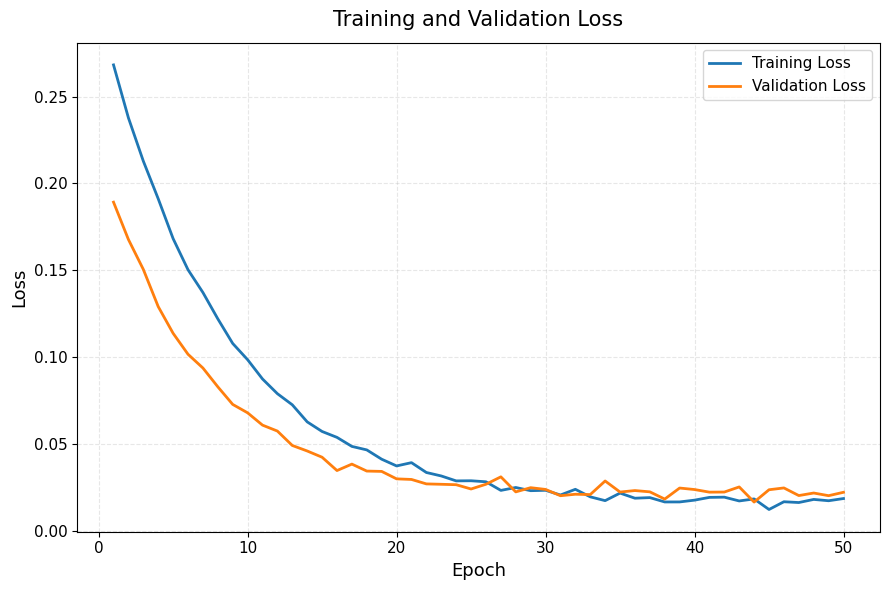

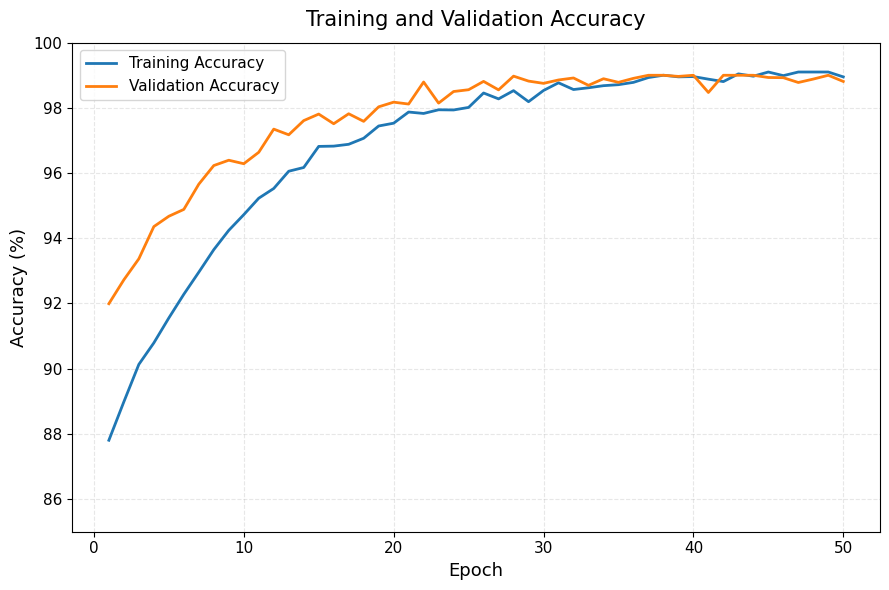

Final Training Loss      : 0.0185
Final Validation Loss    : 0.0221
Final Training Accuracy  : 98.95 %
Final Validation Accuracy: 98.81 %


In [ ]:
ep = np.arange(1, len(HIST["train_acc"]) + 1)

plots = [
    ("train_loss", "val_loss", "Training Loss",     "Validation Loss",     "Loss",
     "Training and Validation Loss",     "DF_SA_MRFO_SAINT_DeepFM_GF_Loss_Curve.png",     1),
    ("train_acc",  "val_acc",  "Training Accuracy", "Validation Accuracy", "Accuracy (%)",
     "Training and Validation Accuracy", "DF_SA_MRFO_SAINT_DeepFM_GF_Accuracy_Curve.png", 100),
]

for key_tr, key_va, lab_tr, lab_va, ylabel, title, fname, scale in plots:
    plt.figure(figsize=(9, 6))
    plt.plot(ep, np.asarray(HIST[key_tr]) * scale, label=lab_tr, linewidth=2)
    plt.plot(ep, np.asarray(HIST[key_va]) * scale, label=lab_va, linewidth=2)
    plt.xlabel("Epoch", fontsize=13)
    plt.ylabel(ylabel, fontsize=13)
    plt.title(title, fontsize=15, pad=12)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)
    plt.legend(fontsize=11, frameon=True)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, fname), dpi=600, bbox_inches="tight")
    plt.show()

print("Final Training Loss      :", round(HIST["train_loss"][-1], 4))
print("Final Validation Loss    :", round(HIST["val_loss"][-1], 4))
print("Final Training Accuracy  :", round(HIST["train_acc"][-1] * 100, 2), "%")
print("Final Validation Accuracy:", round(HIST["val_acc"][-1] * 100, 2), "%")

## Independent test evaluation

Overall performance on the testing set
Performance Metric  Value (%)
          Accuracy      98.89
         Precision      99.22
           Recall       99.17
       Specificity      98.29
          F1-score      99.20

Classification report
                  Precision    Recall    F1-score    Support

Not Pregnant         0.9816    0.9829      0.9823      2340
Pregnant             0.9922    0.9917      0.9920      5160

Accuracy                                   0.9889      7500
Weighted Average     0.9889    0.9889      0.9889      7500
Macro Average        0.9869    0.9873      0.9871      7500


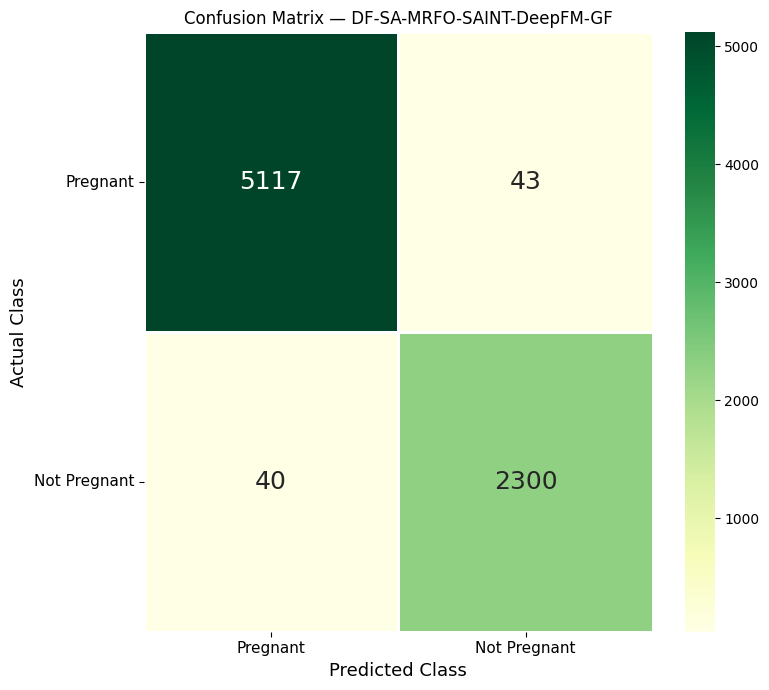

In [ ]:
prob_te = predict_proba(final_model, Xc_te, Xk_te, BEST_HP["batch_size"])
pred_te = (prob_te >= TAU).astype(int)
cm = confusion_matrix(y_test, pred_te)
tn, fp, fn, tp = cm.ravel()
metrics = {
    "Accuracy": accuracy_score(y_test, pred_te) * 100,
    "Precision": precision_score(y_test, pred_te) * 100,
    "Recall ": recall_score(y_test, pred_te) * 100,
    "Specificity": tn / (tn + fp) * 100,
    "F1-score": f1_score(y_test, pred_te) * 100,
}
auc = roc_auc_score(y_test, prob_te)
print("Overall performance on the testing set")
print(pd.DataFrame({"Performance Metric": metrics.keys(), "Value (%)": [round(v, 2) for v in metrics.values()]}).to_string(index=False))

print("Classification report")
print(classification_report(y_test, pred_te, target_names=CLASS_NAMES, digits=4))

cm_disp = np.array([
    [tp, fn],
    [fp, tn]
])

labels = ["Pregnant", "Not Pregnant"]

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_disp,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=True,
    xticklabels=labels,
    yticklabels=labels,
    linewidths=1,
    linecolor="white",
    annot_kws={
        "fontsize": 16,
        "fontweight": "normal"
    }
)

plt.xlabel("Predicted Class", fontsize=13)
plt.ylabel("Actual Class", fontsize=13)
plt.title(
    "Confusion Matrix — DF-SA-MRFO-SAINT-DeepFM-GF",
    fontsize=12
)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

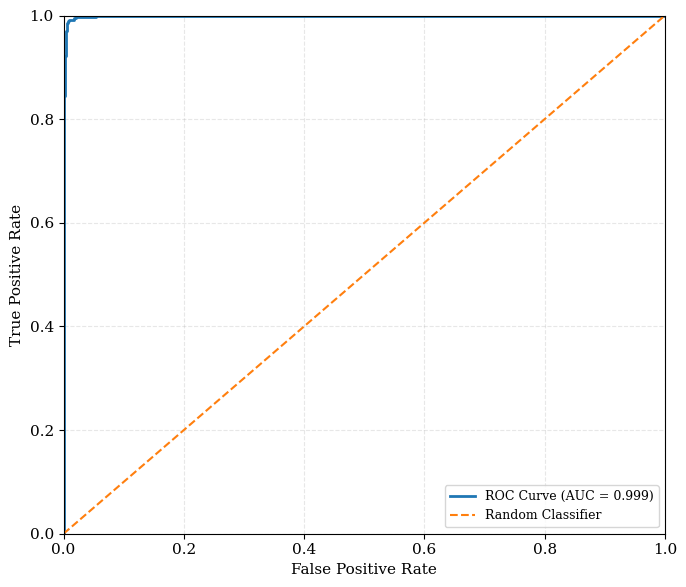

In [ ]:

# ROC CURVE
fpr, tpr, _ = roc_curve(y_test, prob_te)
auc = roc_auc_score(y_test, prob_te)
plt.figure(figsize=(7, 5.5))
plt.plot(
    fpr,
    tpr,
    color="#1f77b4",
    linewidth=2,
    label=f"ROC Curve (AUC = {auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="#ff7f0e",
    linewidth=1.5,
    label="Random Classifier"
)
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

##  95% confidence intervals

In [ ]:
# Define the missing bootstrap configuration constants
N_BOOT = 2000
CI_LEVEL = 0.95

if 'prob_te' not in globals() or 'pred_te' not in globals():
    # Attempt to restore final_model from saved checkpoint if missing
    if 'final_model' not in globals():
        checkpoint_path = os.path.join(OUT_DIR, "df_sa_mrfo_saint_deepfm_gf.pt")
        if os.path.exists(checkpoint_path):
            checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
            BEST_HP = checkpoint["hparams"]
            final_model = SAINTDeepFMGF(Xc_tr.shape[1], CAT_CARDINALITIES, BEST_HP).to(DEVICE)
            final_model.load_state_dict(checkpoint["state_dict"])
            print("Loaded trained model from saved checkpoint successfully.")
        else:
            raise FileNotFoundError("Trained model checkpoint not found on disk. Please run the model training cells first.")

    if 'Xc_te' in globals() and 'Xk_te' in globals():
        prob_te = predict_proba(final_model, Xc_te, Xk_te, BEST_HP["batch_size"])
        pred_te = (prob_te >= TAU).astype(int)
    else:
        raise NameError("Test data 'Xc_te' or 'Xk_te' is missing from the environment.")

def _metrics_from_counts(tp, fn, fp, tn):
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return {"Accuracy": (tp + tn) / (tp + tn + fp + fn), "Precision": prec, "Recall (Sensitivity)": rec,
            "Specificity": tn / max(tn + fp, 1), "F1-score": 2 * prec * rec / max(prec + rec, 1e-12)}

def stratified_bootstrap_ci(y_true, y_pred, y_prob, n_boot=N_BOOT, level=CI_LEVEL, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    draws = {k: [] for k in ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-score", "AUC"]}
    for _ in range(n_boot):
        ip = rng.choice(pos, size=len(pos), replace=True)
        ineg = rng.choice(neg, size=len(neg), replace=True)
        tp = int(y_pred[ip].sum()); fn = len(ip) - tp
        fp = int(y_pred[ineg].sum()); tn = len(ineg) - fp
        for k, v in _metrics_from_counts(tp, fn, fp, tn).items(): draws[k].append(v)
        idx = np.concatenate([ip, ineg])
        draws["AUC"].append(roc_auc_score(y_true[idx], y_prob[idx]))
    lo_q, hi_q = (1 - level) / 2 * 100, (1 + level) / 2 * 100
    return {k: (np.percentile(v, lo_q), np.percentile(v, hi_q)) for k, v in draws.items()}

y_true = np.asarray(y_test).astype(int)
y_hat  = np.asarray(pred_te).astype(int)
CI = stratified_bootstrap_ci(y_true, y_hat, prob_te)

print("95% CI")
for k in ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-score"]:
    print(f"{k:<22}{CI[k][0] * 100:.2f}–{CI[k][1] * 100:.2f} %")
print(f"{'ROC-AUC':<22}{CI['AUC'][0]:.3f}–{CI['AUC'][1]:.3f}")

95% Confidence Intervals (95% CI)
Accuracy                 98.63–99.11 %
Precision                98.95–99.43 %
Recall (Sensitivity)     98.88–99.38 %
Specificity              97.68–98.74 %
F1-score                 99.02–99.36 %


## SHAP explainability


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


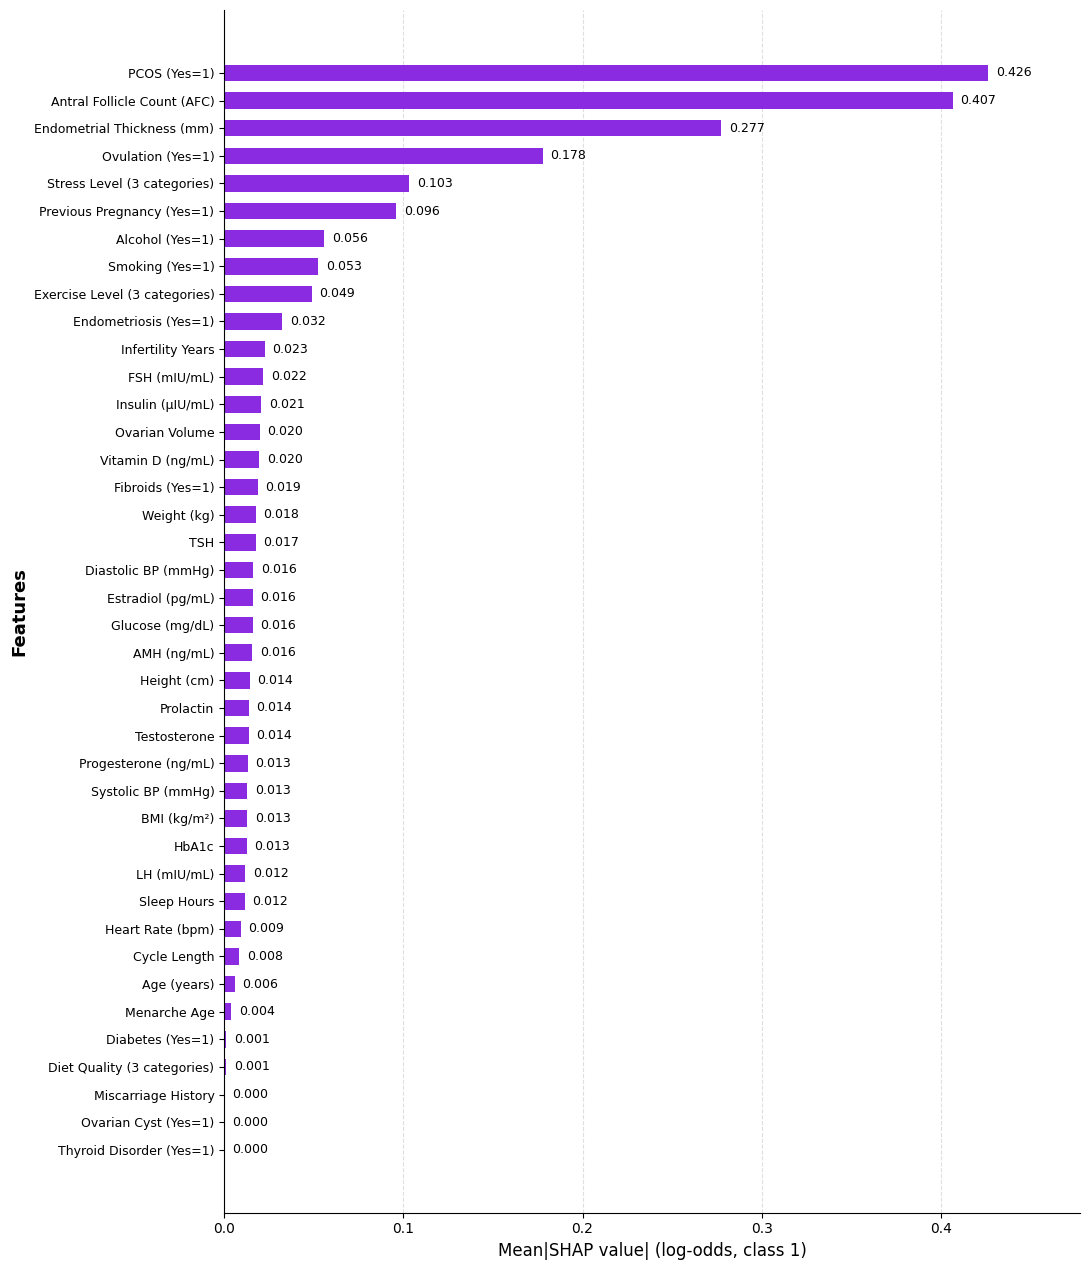

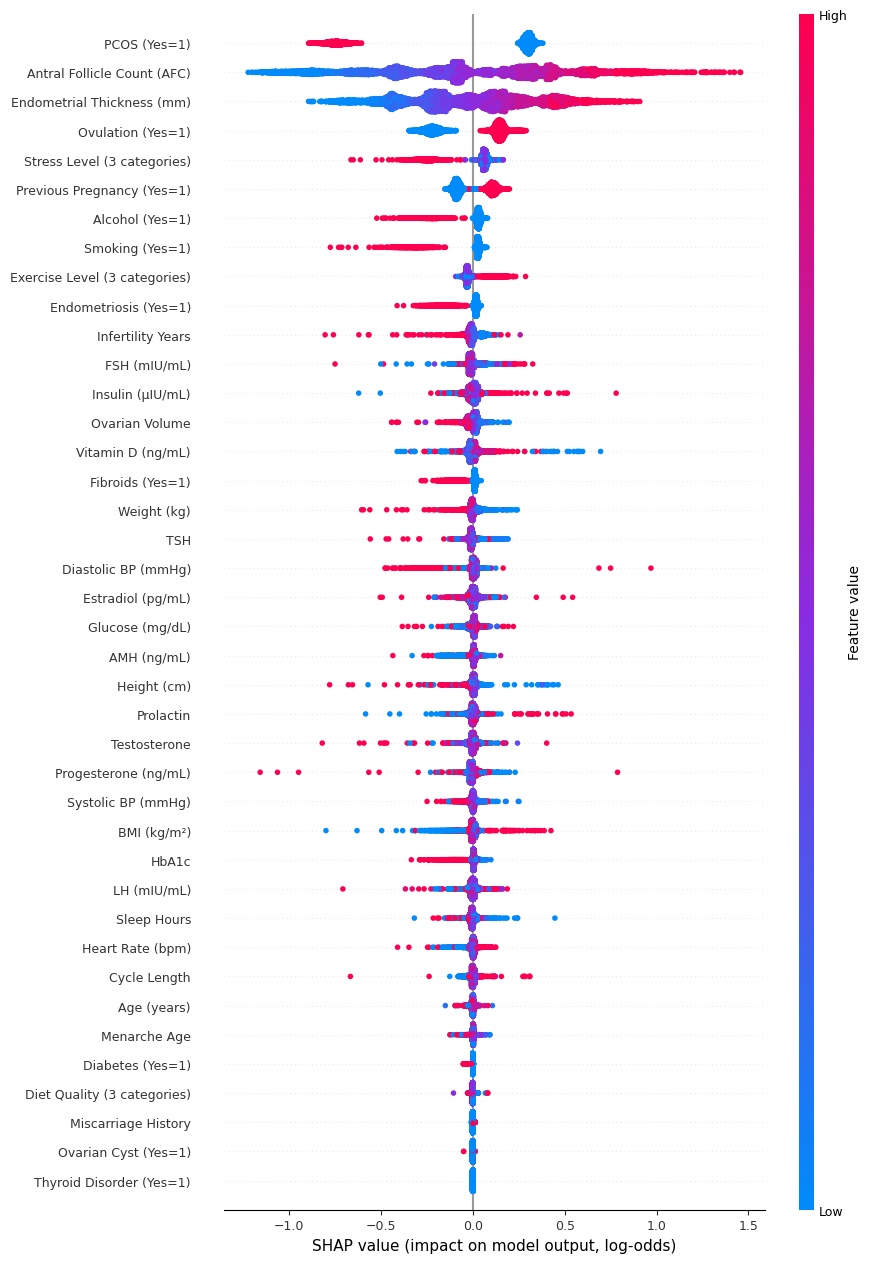

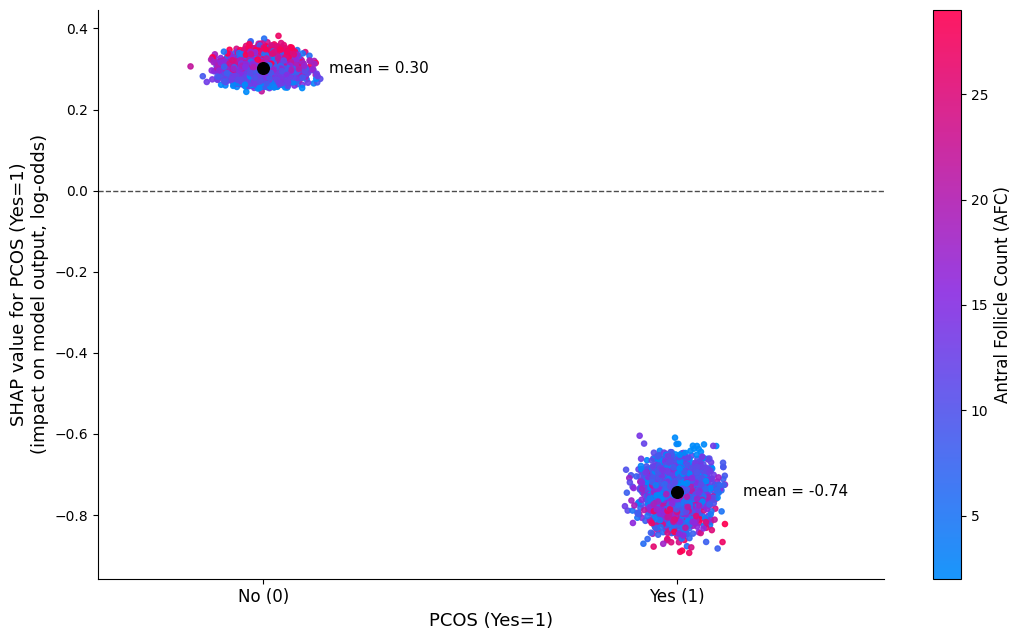

In [ ]:
import re, time
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"]); import shap

#  configuration
SHAP_N_EXPLAIN    = 300
SHAP_N_BACKGROUND = 25
FEATURE_NAMES     = globals().get("FEATURE_NAMES", num_cols + bin_cols + cat_cols)
final_model       = globals().get("final_model", None)
BEST_HP           = globals().get("BEST_HP", None)

if final_model is None or BEST_HP is None:
    raise ValueError("final_model and BEST_HP must be trained and defined in the kernel prior to running SHAP.")

def find_cols(keys):
    return [c for c in FEATURE_NAMES if any(k.lower() in c.lower() for k in keys)]

#  model inputs
n_cont = Xc_te.shape[1]
X_te_model = np.hstack([Xc_te, Xk_te.astype(np.float32)])
X_tr_model = np.hstack([Xc_tr, Xk_tr.astype(np.float32)])
X_te_display = prep.raw_imputed(X_test_raw)[FEATURE_NAMES].values
rng = np.random.default_rng(SEED)
exp_idx = rng.choice(len(X_te_model), size=min(SHAP_N_EXPLAIN, len(X_te_model)), replace=False)
bg_idx = rng.choice(len(X_tr_model), size=min(SHAP_N_BACKGROUND, len(X_tr_model)), replace=False)

ctx_idx = np.random.default_rng(SEED).choice(len(Xc_tr), 127, replace=False)
ctx_c, ctx_k = Xc_tr[ctx_idx], Xk_tr[ctx_idx]

@torch.no_grad()
def shap_logit(Xm):
    final_model.eval(); out = []
    for row in np.asarray(Xm, np.float32):
        c = np.vstack([row[None, :n_cont], ctx_c])
        k = np.vstack([np.rint(row[None, n_cont:]).astype(np.int64), ctx_k])
        lg = final_model(torch.from_numpy(c).to(DEVICE), torch.from_numpy(k).to(DEVICE))
        out.append(lg[0].item())
    return np.array(out)

explainer = shap.KernelExplainer(shap_logit, X_tr_model[bg_idx])
t0 = time.time()
sv_vals = explainer.shap_values(X_te_model[exp_idx],
                                nsamples=2*len(FEATURE_NAMES) + 2048, seed=SEED)
print(f"SHAP finished in {(time.time()-t0)/60:.1f} min")

mean_abs = pd.Series(np.abs(sv_vals).mean(0), index=FEATURE_NAMES).sort_values(ascending=False)
mean_abs.round(4).to_csv(os.path.join(OUT_DIR, "shap_mean_abs.csv"), header=["mean_abs_shap"])

# global SHAP feature

DISPLAY = {
    "pcos": "PCOS (Yes=1)", "afc": "Antral Follicle Count (AFC)", "endometrialthickness": "Endometrial Thickness (mm)",
    "ovulation": "Ovulation (Yes=1)", "stresslevel": "Stress Level (3 categories)",
    "previouspregnancy": "Previous Pregnancy (Yes=1)", "alcohol": "Alcohol (Yes=1)", "smoking": "Smoking (Yes=1)",
    "exerciselevel": "Exercise Level (3 categories)", "endometriosis": "Endometriosis (Yes=1)", "infertilityyears": "Infertility Years",
    "fsh": "FSH (mIU/mL)", "insulin": "Insulin (IU/mL)", "ovarianvolume": "Ovarian Volume",
    "vitamind": "Vitamin D (ng/mL)", "fibroids": "Fibroids (Yes=1)", "weightkg": "Weight (kg)", "weight": "Weight (kg)",
    "tsh": "TSH", "diastolicbp": "Diastolic BP (mmHg)", "estradiol": "Estradiol (pg/mL)", "glucose": "Glucose (mg/dL)",
    "amh": "AMH (ng/mL)", "heightcm": "Height (cm)", "height": "Height (cm)", "prolactin": "Prolactin",
    "testosterone": "Testosterone", "progesterone": "Progesterone (ng/mL)", "systolicbp": "Systolic BP (mmHg)",
    "bmi": "BMI (kg/m)", "hba1c": "HbA1c", "lh": "LH (mIU/mL)", "sleephours": "Sleep Hours",
    "heartrate": "Heart Rate (bpm)", "cyclelength": "Cycle Length", "age": "Age (years)", "menarcheage": "Menarche Age",
    "diabetes": "Diabetes (Yes=1)", "dietquality": "Diet Quality (3 categories)", "miscarriagehistory": "Miscarriage History",
    "ovariancyst": "Ovarian Cyst (Yes=1)", "thyroiddisorder": "Thyroid Disorder (Yes=1)"}
pretty = lambda c: DISPLAY.get(re.sub(r"[^a-z0-9]", "", c.lower()), c.replace("_", " "))

top = mean_abs[::-1]
with plt.rc_context({"font.family": "serif"}):
    fig, ax = plt.subplots(figsize=(10.5, max(7, 0.30 * len(top) + 1.5)))
    bars = ax.barh([pretty(c) for c in top.index], top.values, height=0.6, color="#8A2BE2", zorder=3)
    for b, v in zip(bars, top.values):
        ax.text(v + top.max() * 0.012, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlabel("Mean|SHAP value| (log-odds, class 1)", fontsize=12)
    ax.set_ylabel("Features", fontsize=12, fontweight="bold")
    ax.set_xlim(0, top.max() * 1.18); ax.set_ylim(-1.5, len(top) + 0.5)
    ax.grid(axis="x", linestyle="--", alpha=0.35, zorder=0)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=9)
    save_fig("shap_importance.png")


# SHAP beeswarm plot

plt.figure()
shap.summary_plot(sv_vals, X_te_display[exp_idx], feature_names=FEATURE_NAMES, max_display=20, show=False)
plt.title("SHAP summary (beeswarm) plot")
save_fig("shap_beeswarm.png")


# SHAP dependence plot

top_feature = mean_abs.index[0]
color_feature = find_cols(["AFC"])[0] if find_cols(["AFC"]) else "auto"
shap.dependence_plot(top_feature, sv_vals, X_te_display[exp_idx], feature_names=FEATURE_NAMES,
                     interaction_index=color_feature, show=False, dot_size=18, alpha=0.8)
plt.gcf().set_size_inches(7.5, 5.5)
plt.title(f"SHAP dependence plot — {top_feature} (colour: {color_feature})")
save_fig("shap_dependence.png")